# Part 1 - Data preparation and quality
**Industrial AI for Manufacturing - Mini Project 1 (B4)** - CRISP-DM.
This is **notebook 1 of 4**. It prepares everything the other parts need.

**Data:** two PLC logs of one recorded production batch, plus a signal dictionary (in `../data/raw/`).
The Siemens S7 log covers the oven, drill, turntable and sorting (about one row every 76 ms).
The Beckhoff log covers the warehouse, robot and operator screen (about one row every 93 ms).

**Question of the project:** where does the line lose time - brief pauses, slow steps, or waiting between stations?

**Hypotheses:** L1 slow steps, L2 robot transfers cause waiting, L3 pauses between completed parts,
L4 one station causes most delay. (The earlier fifth hypothesis - "data gaps can look like machine
delays" - is handled here as data-quality checks, not as a hypothesis.)

**The four parts:** 1 data preparation and quality (this notebook) - 2 rule-based event detection -
3 clustering model - 4 evaluation and comparison. Run them in order.

**How the two logs are combined (the method agreed for this project):**

- One fixed **85 ms grid**. Every grid time gets the **last recorded value** of each log, never a value from the future.
- Every grid row also keeps **where its values came from** and **how old they are**. A stale value stays visible instead of looking fresh.
- Steps and stops are **measured on the original timestamps** of each log, not on the grid, because the grid can shift a recorded change by up to 85 ms.
- Unknown values are left empty. They are not turned into OFF, because "no record" does not mean "signal off".
- The two PLC clocks are **assumed** to run together. Nobody checked this. So when both logs see the same event, the notebook says "recorded close together", not "happened at the same instant".

This first block loads the libraries and sets up the folders and the fixed numbers used in all four parts: the 85 ms time grid and the rule for when a step counts as slow. Keeping them in one place means every notebook works with the same settings.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '../data/raw/'       # original files (never changed)
OUT_DIR = '../data/processed'   # the joined table
RES_DIR = '../results'          # result tables
FIG_DIR = '../results/figures'  # charts
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

GRID_MS = 85        # time step of the joined table
SLOW_FACTOR = 1.25  # a step is "slow" at 25 % above its normal time ...
MIN_EXTRA_S = 2.0   # ... and at least 2 s above it (own assumption, agreed in the team)
MIN_REPEATS = 5     # normal time only for steps repeating at least 5 times


## 1. Load the two original logs
No signal column is removed. Only the empty column created by the `;` at the end of each line is dropped.
`True/False` becomes `1/0`, numbers become numbers. The last Siemens row is cut off (empty cells) and is dropped.

This block reads the two original PLC logs. Each file is first read as text, then every column gets its real type: True/False becomes 1/0 and numbers with a comma become proper numbers. Empty Siemens rows are removed, and both logs get a shared time zero so their times can be compared.

In [2]:
def load_log(file_name):
    # read one PLC log as text first, then give each column its real type
    df = pd.read_csv(DATA_DIR + file_name, sep=';', dtype=str)
    df = df.loc[:, ~df.columns.str.startswith('Unnamed')]  # empty column from the trailing ';'
    df = df.rename(columns={'timestamp': 'ts_ms'})
    df['ts_ms'] = df['ts_ms'].astype('int64')  # Unix time in milliseconds
    for col in df.columns[1:]:
        if set(df[col].dropna().unique()) <= {'True', 'False'}:
            df[col] = df[col].map({'True': 1.0, 'False': 0.0})
        else:
            df[col] = pd.to_numeric(df[col].str.replace(',', '.'), errors='coerce')
    return df


beck = load_log('Beispieldatensatz_Beckhoff_SPS.csv')
sie = load_log('Beispieldatensatz_Siemens_S7_SPS.csv')
print('Beckhoff:', beck.shape, '| Siemens:', sie.shape)

rows_before = len(sie)
sie = sie.dropna().reset_index(drop=True)
print('Siemens rows dropped because of empty cells:', rows_before - len(sie))
print('Beckhoff rows with empty cells:', int(beck.isna().any(axis=1).sum()))

T0 = min(beck['ts_ms'].min(), sie['ts_ms'].min())  # common time zero (Unix ms)
T_END = min(beck['ts_ms'].max(), sie['ts_ms'].max())
for df in (beck, sie):
    df['ms'] = df['ts_ms'] - T0    # milliseconds from time zero
    df['src_ms'] = df['ms']        # this row's own time, kept as "source"


Beckhoff: (5197, 54) | Siemens: (6283, 143)
Siemens rows dropped because of empty cells: 1
Beckhoff rows with empty cells: 0


## 2. One combined table on a fixed 85 ms grid
The two PLCs sample at different speeds, so rows cannot be matched one to one.
I build a fixed grid of **85 ms** and give every grid time the **last known value** of each log
(`direction='backward'`, so no value from the future is used). Time zero is the first reading of either log.

Two extra pairs of columns are important: `BECK_src_ms` / `SIE_src_ms` remember **which original record**
each value came from, and `BECK_age_ms` / `SIE_age_ms` tell **how old** the value is at that grid time.
Before a log's first record there is simply no value - the cells stay empty instead of being filled with a guessed 0.

Here the two logs are joined into one table. We build a fixed grid with one row every 85 ms and fill each row with the newest value each log had at that moment. No values are averaged or invented, and for every value we keep its age, so we can later see where the data was already old.

In [3]:
print(f"Median interval: Beckhoff {beck['ts_ms'].diff().median():.0f} ms, "
      f"Siemens {sie['ts_ms'].diff().median():.0f} ms -> grid {GRID_MS} ms")

grid = pd.DataFrame({'ms': np.arange(0, T_END - T0 + 1, GRID_MS)})  # 0, 85, 170, ...

b = beck.drop(columns='ts_ms').add_prefix('BECK_').rename(columns={'BECK_ms': 'ms'})
s = sie.drop(columns='ts_ms').add_prefix('SIE_').rename(columns={'SIE_ms': 'ms'})

data = pd.merge_asof(grid, b, on='ms', direction='backward')  # grid + Beckhoff
data = pd.merge_asof(data, s, on='ms', direction='backward')  # + Siemens

data.insert(0, 'unix_ms', T0 + data['ms'])
data.insert(2, 'utc_time', pd.to_datetime(data['unix_ms'], unit='ms')
            .dt.strftime('%Y-%m-%d %H:%M:%S.%f').str[:-3])
data.insert(3, 't_s', data['ms'] / 1000)  # seconds from start
for plc in ('BECK', 'SIE'):
    data[plc + '_age_ms'] = data['ms'] - data[plc + '_src_ms']

data.to_csv(OUT_DIR + '/aligned_all_columns_85ms.csv', index=False)
print(f"Joined table: {data.shape} | from {data['utc_time'].iloc[0]} "
      f"to {data['utc_time'].iloc[-1]}")
for plc in ('BECK', 'SIE'):
    age = data[plc + '_age_ms']
    print(f'{plc} value age: median {age.median():.0f} ms, worst {age.max():.0f} ms, '
          f'rows older than 250 ms: {(age > 250).sum()}, '
          f'values from the future: {(age < 0).sum()}, '
          f'rows with no value yet: {age.isna().sum()}')
data.iloc[:4, :8]


Median interval: Beckhoff 93 ms, Siemens 76 ms -> grid 85 ms


Joined table: (5950, 203) | from 2019-09-26 18:21:14.515 to 2019-09-26 18:29:40.180
BECK value age: median 49 ms, worst 1812 ms, rows older than 250 ms: 48, values from the future: 0, rows with no value yet: 5
SIE value age: median 40 ms, worst 1663 ms, rows older than 250 ms: 122, values from the future: 0, rows with no value yet: 0


,unix_ms,ms,utc_time,t_s,BECK_VG.I1_ref_switch_vertical,BECK_VG.I2_ref_switch_horizontal,BECK_VG.I3_ref_switch_rotate,BECK_VG.B1_encoder_vertical_impulse1
0,1569522074515,0,2019-09-26 18:21:14.515,0.000,NaN,NaN,NaN,NaN
1,1569522074600,85,2019-09-26 18:21:14.600,0.085,NaN,NaN,NaN,NaN
2,1569522074685,170,2019-09-26 18:21:14.685,0.170,NaN,NaN,NaN,NaN
3,1569522074770,255,2019-09-26 18:21:14.770,0.255,NaN,NaN,NaN,NaN


## 3. Data-quality checks (before trusting anything)
A gap in a log can make a step look longer, so the checks come first:
1. How regular are the timestamps, and where are the gaps?
2. Do both PLCs record the same stop at about the same time? (This also tests the join.)

Keep in mind for the whole project: **the two PLC clocks are assumed to agree, but this was never checked.**
All cross-PLC time comparisons carry that assumption.

This block checks the quality of the raw logs before we trust them. It finds every place where a log was silent for more than 300 ms and counts problems such as duplicate or backward-running timestamps and missing values.

In [4]:
def find_gaps(df, plc, min_gap_ms=300):
    # all places where one log was silent for more than min_gap_ms
    dt = df['ts_ms'].diff()
    idx = dt[dt > min_gap_ms].index
    return pd.DataFrame({'plc': plc,
                         'gap_start_s': (df['ts_ms'].shift(1)[idx] - T0) / 1000,
                         'gap_end_s': (df['ts_ms'][idx] - T0) / 1000,
                         'gap_s': dt[idx] / 1000})

gaps = pd.concat([find_gaps(beck, 'Beckhoff'), find_gaps(sie, 'Siemens')])
gaps = gaps.reset_index(drop=True)

rows = []
for name, df in [('Beckhoff', beck), ('Siemens', sie)]:
    dt = df['ts_ms'].diff().dropna()
    rows.append((name, len(df), dt.median(), dt.max(), int((dt > 300).sum()),
                 int((dt > 1000).sum()), int((dt == 0).sum()),
                 int((dt < 0).sum()), int(df.isna().sum().sum())))
quality = pd.DataFrame(rows, columns=['PLC', 'rows', 'median_ms', 'max_ms',
                                      'gaps_over_300ms', 'gaps_over_1s',
                                      'duplicate_timestamps', 'backward_timestamps',
                                      'missing_values'])
for name, df in [('Beckhoff', beck), ('Siemens', sie)]:
    numeric = [c for c in df.columns[1:]
               if not set(df[c].dropna().unique()) <= {0.0, 1.0}]
    constant = [c for c in df.columns[1:] if df[c].nunique() <= 1]
    print(f'{name}: {len(numeric)} columns are not 0/1 (numbers or counters), '
          f'{len(constant)} columns never change')

gaps.round(3).to_csv(RES_DIR + '/logging_gaps.csv', index=False)
quality.to_csv(RES_DIR + '/data_quality.csv', index=False)
print('saved: results/logging_gaps.csv, results/data_quality.csv')
quality


Beckhoff: 5 columns are not 0/1 (numbers or counters), 8 columns never change
Siemens: 12 columns are not 0/1 (numbers or counters), 32 columns never change
saved: results/logging_gaps.csv, results/data_quality.csv


,PLC,rows,median_ms,max_ms,gaps_over_300ms,gaps_over_1s,duplicate_timestamps,backward_timestamps,missing_values
0,Beckhoff,5197,93.0,1841.0,9,1,0,0,0
1,Siemens,6282,76.0,1722.0,31,4,0,0,0


Two checks in one block. The chart shows the time between two log rows, so silent periods appear as high dots. Then we compare the light curtain, which both PLCs record: if the join worked, both sides must show it at almost the same time.

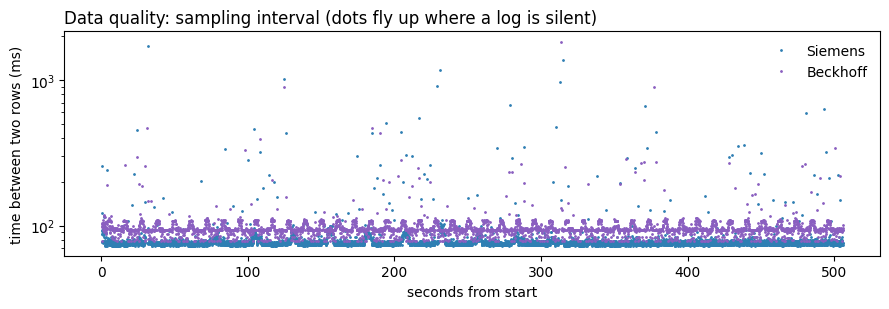

Both PLCs record the 3 curtain stops within about 0.09 s of each other.
Note: "recorded close together", not proof of the same instant -
the two PLC clocks were never checked against each other.


,siemens_start_s,siemens_end_s,beckhoff_start_s,beckhoff_end_s,start_diff_s,end_diff_s
0,255.396,264.292,255.487,264.263,0.091,-0.029
1,390.061,400.438,390.100,400.396,0.039,-0.042
2,453.141,460.743,453.190,460.772,0.049,0.029


In [5]:
def pulses(df, col, level=1):
    # (start, end) pairs of complete periods where df[col] == level,
    # measured on the log's own timestamps, in ms from time zero
    x = (df[col] == level).astype(int)
    change = x.diff()
    starts = df.loc[change[change == 1].index, 'ms']
    ends = df.loc[change[change == -1].index, 'ms']
    return [(s, ends[ends > s].iloc[0]) for s in starts if (ends > s).any()]

# chart: sampling interval over time, gaps visible as high dots
fig, ax = plt.subplots(figsize=(9, 3.2))
for name, df, color in [('Siemens', sie, '#2f7fb3'), ('Beckhoff', beck, '#8a5fc0')]:
    ax.plot(df['ms'][1:] / 1000, df['ts_ms'].diff()[1:], '.', ms=2,
            color=color, label=name)
ax.set_yscale('log')
ax.set_xlabel('seconds from start')
ax.set_ylabel('time between two rows (ms)')
ax.set_title('Data quality: sampling interval (dots fly up where a log is silent)',
             loc='left')
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR + '/data_quality_sampling.png', dpi=150)
plt.show()

# the light curtain is seen by BOTH PLCs - a natural check of the join
curtain = pd.DataFrame([(a / 1000, b / 1000) for a, b in pulses(sie, 'A201.0', level=0)],
                       columns=['siemens_start_s', 'siemens_end_s'])
beck_curtain = pd.DataFrame(
    [(a / 1000, b / 1000) for a, b in pulses(beck, 'VG.safeCurtainShort', level=0)],
    columns=['beckhoff_start_s', 'beckhoff_end_s'])
curtain = curtain.join(beck_curtain)
curtain['start_diff_s'] = curtain['beckhoff_start_s'] - curtain['siemens_start_s']
curtain['end_diff_s'] = curtain['beckhoff_end_s'] - curtain['siemens_end_s']
curtain.round(3).to_csv(RES_DIR + '/curtain_both_plcs.csv', index=False)
worst = curtain[['start_diff_s', 'end_diff_s']].abs().max().max()
print(f'Both PLCs record the 3 curtain stops within about {worst:.2f} s of each other.')
print('Note: "recorded close together", not proof of the same instant -')
print('the two PLC clocks were never checked against each other.')
curtain.round(3)


**Done.** The joined table is in `data/processed/`, the quality tables in `results/`.
Next: `part2_rule_based_detection/02_rule_based_detection.ipynb`.